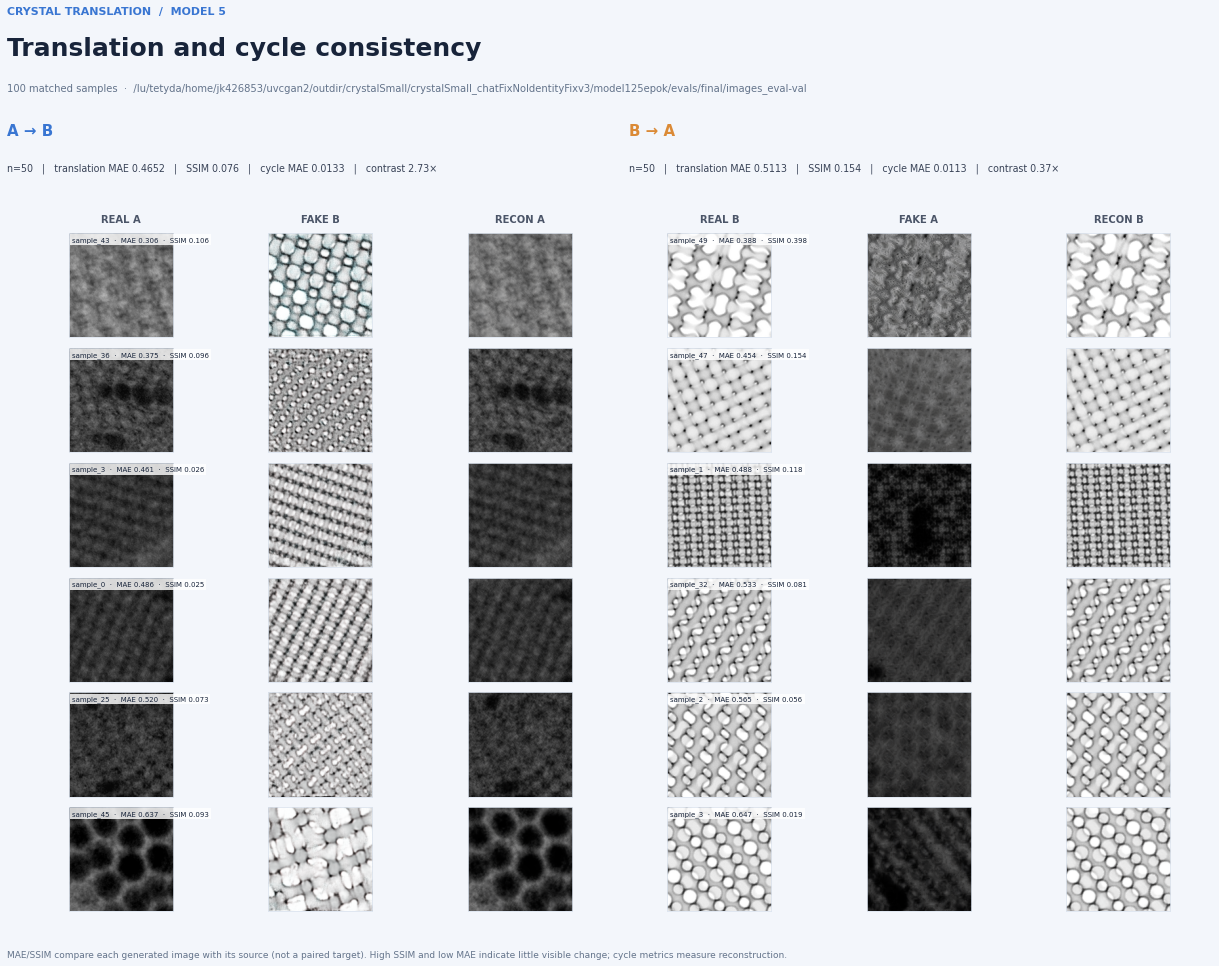

In [5]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

data = "/lu/tetyda/home/jk426853/uvcgan2/outdir/crystalSmall/crystalSmall_chatFixNoIdentityFixv3/model125epok/evals/final/images_eval-val"
eval_dir = Path(data)

flows = [
    {"title": "A → B", "source": "real_a", "generated": "fake_b", "reconstruction": "reco_a", "color": "#3976d2"},
    {"title": "B → A", "source": "real_b", "generated": "fake_a", "reconstruction": "reco_b", "color": "#db8a36"},
]

def load_rgb(folder, sample_id):
    with Image.open(eval_dir / folder / f"{sample_id}.png") as image:
        return image.convert("RGB").copy()

def image_ssim(image_a, image_b, window_size=11):
    """Mean RGB SSIM using a local uniform window (NumPy only)."""
    a = np.asarray(image_a, dtype=np.float32) / 255.0
    b = np.asarray(image_b, dtype=np.float32) / 255.0
    if a.shape != b.shape:
        raise ValueError(f"Image shapes differ: {a.shape} and {b.shape}")
    window_size = min(window_size, *a.shape[:2])
    if window_size % 2 == 0:
        window_size -= 1
    if window_size < 1:
        raise ValueError("Images must not be empty")

    def local_mean(values):
        integral = np.pad(values, ((1, 0), (1, 0)), mode="constant")
        integral = integral.cumsum(axis=0).cumsum(axis=1)
        sums = (
            integral[window_size:, window_size:]
            - integral[:-window_size, window_size:]
            - integral[window_size:, :-window_size]
            + integral[:-window_size, :-window_size]
        )
        return sums / window_size ** 2

    c1, c2 = 0.01 ** 2, 0.03 ** 2
    scores = []
    for channel in range(3):
        x, y = a[:, :, channel], b[:, :, channel]
        mean_x, mean_y = local_mean(x), local_mean(y)
        var_x = np.maximum(local_mean(x * x) - mean_x * mean_x, 0)
        var_y = np.maximum(local_mean(y * y) - mean_y * mean_y, 0)
        covariance = local_mean(x * y) - mean_x * mean_y
        score = (
            (2 * mean_x * mean_y + c1) * (2 * covariance + c2)
            / ((mean_x ** 2 + mean_y ** 2 + c1) * (var_x + var_y + c2))
        )
        scores.append(float(score.mean()))
    return float(np.mean(scores))

if not eval_dir.is_dir():
    raise FileNotFoundError(f"Evaluation directory not found: {eval_dir}")

for flow in flows:
    folders = (flow["source"], flow["generated"], flow["reconstruction"])
    sample_sets = [
        {path.stem for path in (eval_dir / folder).glob("sample_*.png")}
        for folder in folders
    ]
    sample_ids = sorted(
        set.intersection(*sample_sets),
        key=lambda sample_id: int(sample_id.rsplit("_", 1)[1]),
    )
    if not sample_ids:
        raise FileNotFoundError(f"No matching images found for {flow['title']}")

    flow["rows"] = []
    for sample_id in sample_ids:
        source = load_rgb(flow["source"], sample_id)
        generated = load_rgb(flow["generated"], sample_id)
        reconstruction = load_rgb(flow["reconstruction"], sample_id)
        source_array = np.asarray(source, dtype=np.float32) / 255.0
        generated_array = np.asarray(generated, dtype=np.float32) / 255.0
        reconstruction_array = np.asarray(reconstruction, dtype=np.float32) / 255.0
        flow["rows"].append({
            "id": sample_id,
            "source": source,
            "generated": generated,
            "reconstruction": reconstruction,
            "translation_mae": float(np.abs(source_array - generated_array).mean()),
            "translation_ssim": image_ssim(source, generated),
            "cycle_mae": float(np.abs(source_array - reconstruction_array).mean()),
            "cycle_ssim": image_ssim(source, reconstruction),
            "contrast_ratio": float(generated_array.std() / max(float(source_array.std()), 1e-8)),
        })

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})
fig = plt.figure(figsize=(18, 14), facecolor="#f3f6fb")
grid = fig.add_gridspec(
    7, 6, left=0.07, right=0.985, top=0.76, bottom=0.07,
    hspace=0.12, wspace=0.06, height_ratios=[0.06] + [1] * 6,
)
fig.text(0.055, 0.96, "CRYSTAL TRANSLATION  /  MODEL 5", fontsize=11, color="#3976d2", weight="bold")
fig.text(0.055, 0.92, "Translation and cycle consistency", fontsize=25, color="#18243a", weight="bold")
fig.text(0.055, 0.885, f"{sum(len(flow['rows']) for flow in flows)} matched samples  ·  {eval_dir}", fontsize=10, color="#64748b")

for index, flow in enumerate(flows):
    rows = flow["rows"]
    x = 0.055 + index * 0.48
    fig.text(x, 0.84, flow["title"], fontsize=15, color=flow["color"], weight="bold")
    fig.text(
        x, 0.805,
        f"n={len(rows)}   |   translation MAE {np.mean([r['translation_mae'] for r in rows]):.4f}"
        f"   |   SSIM {np.mean([r['translation_ssim'] for r in rows]):.3f}"
        f"   |   cycle MAE {np.mean([r['cycle_mae'] for r in rows]):.4f}"
        f"   |   contrast {np.mean([r['contrast_ratio'] for r in rows]):.2f}×",
        fontsize=9.5, color="#394357",
    )

for column, label in enumerate(("REAL A", "FAKE B", "RECON A", "REAL B", "FAKE A", "RECON B")):
    axis = fig.add_subplot(grid[0, column])
    axis.axis("off")
    axis.text(0.5, 0.5, label, ha="center", va="center", color="#4b5568", weight="bold")

# Show six samples spanning low-to-high translation error in each direction.
for flow_index, flow in enumerate(flows):
    rows = sorted(flow["rows"], key=lambda row: row["translation_mae"])
    selected_indices = np.unique(np.round(np.linspace(0, len(rows) - 1, 6)).astype(int))
    for display_row, selected_index in enumerate(selected_indices):
        row = rows[selected_index]
        images = (row["source"], row["generated"], row["reconstruction"])
        for image_index, image in enumerate(images):
            column = flow_index * 3 + image_index
            axis = fig.add_subplot(grid[display_row + 1, column])
            axis.imshow(image)
            axis.set_xticks([])
            axis.set_yticks([])
            for spine in axis.spines.values():
                spine.set_color("#dce4ef")
                spine.set_linewidth(0.8)
            if image_index == 0:
                axis.text(
                    0.03, 0.97,
                    f"{row['id']}  ·  MAE {row['translation_mae']:.3f}  ·  SSIM {row['translation_ssim']:.3f}",
                    transform=axis.transAxes, ha="left", va="top", fontsize=7,
                    color="#18243a", bbox={"facecolor": "white", "alpha": 0.82, "edgecolor": "none", "pad": 2},
                )

fig.text(
    0.055, 0.025,
    "MAE/SSIM compare each generated image with its source (not a paired target). "
    "High SSIM and low MAE indicate little visible change; cycle metrics measure reconstruction.",
    fontsize=9, color="#64748b",
)
plt.show()
plt.close(fig)